# Resúmenes de los artículos de la revisión de literatura

Un resumen por cada artículo analizado: qué hicieron los autores, cómo configuraron el estudio y para qué usaron cada método. **No** se explica cómo funciona cada método; cuando un método ya está explicado en el [notebook de métodos](../metodos/metodos.ipynb), se enlaza a su sección.

Estructura de cada artículo: Referencia → Problema → Pregunta → Cómo lo resolvieron (configuración y procedimiento paso a paso, con figuras) → Métodos y propósito → Validación y resultados → Limitaciones → Conclusiones.

Las figuras son **esquemas propios** generados con matplotlib para ilustrar lo que hicieron los autores; no son copias ni redibujos de las figuras de los artículos. También se guardan como PNG en `figuras/`.

## Tabla de contenido

| Autores | Año | Título corto |
|---|---|---|
| [Malekjafarian y OBrien](#malekjafarian-obrien-2017) | 2017 | Uso de un vehículo que pasa para estimar las formas modales de un puente |

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

COLOR_SIGNAL = "#8a8984"   # neutral gray
COLOR_1 = "#2a78d6"        # blue
COLOR_2 = "#eb6834"        # orange
COLOR_TRUE = "#0b0b0b"     # exact reference / ink

FIG_DIR = Path("figuras")  # PNG copies of every figure
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "legend.frameon": False,
})

<a id="malekjafarian-obrien-2017"></a>
# Malekjafarian y OBrien (2017)

## 1. Referencia

Malekjafarian, A. y OBrien, E. J. (2017). *On the use of a passing vehicle for the estimation of bridge mode shapes*. Journal of Sound and Vibration, 397, 77–91. https://doi.org/10.1016/j.jsv.2017.02.051. University College Dublin.

## 2. Problema

Medir las formas modales de un puente con sensores fijos es caro, porque hay que instrumentar cada puente. Con un vehículo que pasa es más barato, pero la respuesta del puente queda tapada por la del vehículo y la rugosidad, y la amplitud medida no es directamente la forma modal, porque el tamaño de la vibración cambia mientras el vehículo cruza.

## 3. Pregunta

¿Se pueden estimar las formas modales de un puente a partir de las aceleraciones medidas en un vehículo que pasa, excitando el puente desde el propio vehículo?

## 4. Cómo lo resolvieron

### Configuración del estudio

Todo es simulación numérica en MATLAB, con interacción vehículo-puente:

- **Puente:** viga simplemente apoyada de 15 m, con frecuencias naturales de 5.65, 22.62 y 50.89 Hz.
- **Vehículo:** convoy formado por un camión de 3 ejes y dos remolques, cruzando a 2 m/s.
- **Excitador:** va en el eje 4, que es el primer eje del primer remolque. Aplica una fuerza senoidal (3 kN con carretera lisa y 30 kN con rugosidad clase A) a una frecuencia cercana a la del modo que se quiere obtener.
- **Sensores:** acelerómetros en los ejes 6 y 7, en el segundo remolque, separados 1 m. Solo miden; no excitan.
- **Dos pasadas:** una con el excitador a 5.5 Hz, para el primer modo, y otra a 22.9 Hz, para el segundo.

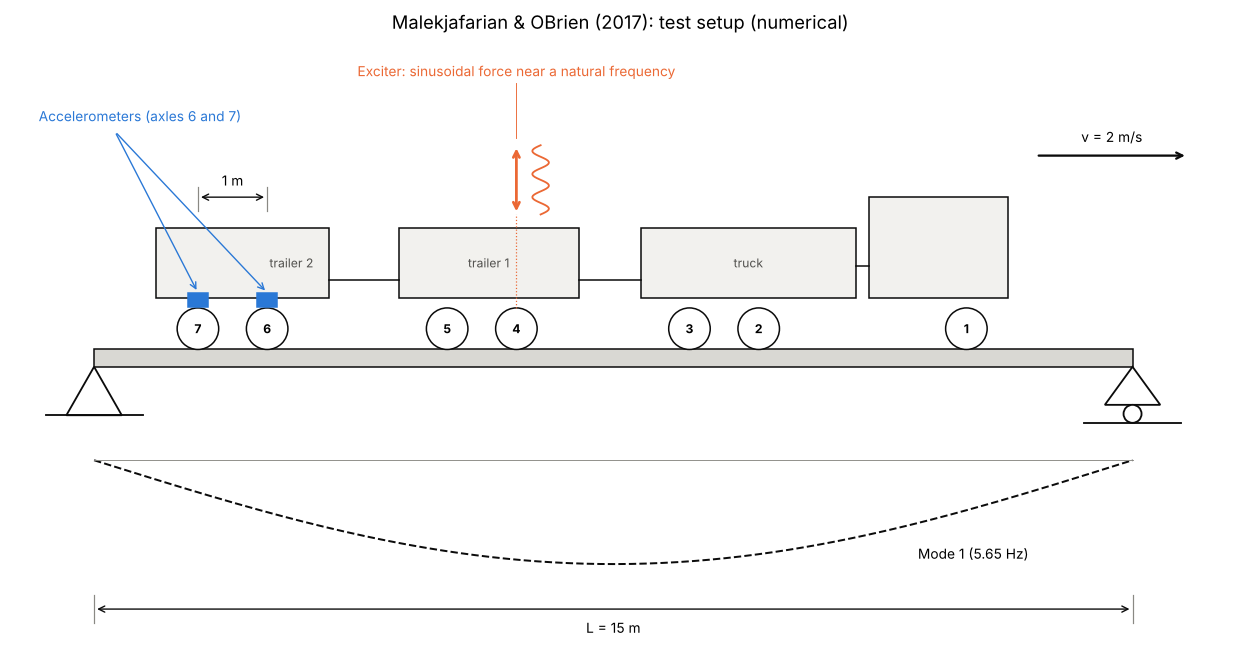

In [2]:
# Figure 1: test setup (schematic, not to scale except the 1 m axle spacing 6-7)
L = 15.0
fig, ax = plt.subplots(figsize=(12, 6.2))

# --- Bridge deck and supports ---
ax.add_patch(patches.Rectangle((0, -0.25), L, 0.25, facecolor="#d9d8d3", edgecolor=COLOR_TRUE, lw=1))
ax.add_patch(patches.Polygon([(0, -0.25), (-0.4, -0.95), (0.4, -0.95)], closed=True,
                             facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))            # pin
ax.add_patch(patches.Polygon([(L, -0.25), (L - 0.4, -0.8), (L + 0.4, -0.8)], closed=True,
                             facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))            # roller
ax.add_patch(patches.Circle((L, -0.93), 0.13, facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))
ax.plot([-0.7, 0.7], [-0.95, -0.95], color=COLOR_TRUE, lw=1.2)
ax.plot([L - 0.7, L + 0.7], [-1.06, -1.06], color=COLOR_TRUE, lw=1.2)

# --- Vehicle: axle positions (m); driving direction to the right ---
axles = {7: 1.5, 6: 2.5, 5: 5.1, 4: 6.1, 3: 8.6, 2: 9.6, 1: 12.6}
wheel_r = 0.3
bodies = [(0.9, 3.4, 1.0), (4.4, 7.0, 1.0), (7.9, 11.0, 1.0)]   # (x0, x1, height)
for x0, x1, h in bodies:
    ax.add_patch(patches.Rectangle((x0, 0.75), x1 - x0, h, facecolor="#f2f1ee",
                                   edgecolor=COLOR_TRUE, lw=1))
ax.add_patch(patches.Rectangle((11.2, 0.75), 2.0, 1.45, facecolor="#f2f1ee",
                               edgecolor=COLOR_TRUE, lw=1))                           # truck cab
ax.plot([11.0, 11.2], [1.2, 1.2], color=COLOR_TRUE, lw=1)
ax.plot([3.4, 4.4], [1.0, 1.0], color=COLOR_TRUE, lw=1)                                  # couplings
ax.plot([7.0, 7.9], [1.0, 1.0], color=COLOR_TRUE, lw=1)
for name, (x0, x1, _) in zip(["trailer 2", "trailer 1", "truck"], bodies):
    label_x = x1 - 0.55 if name == "trailer 2" else (x0 + x1) / 2   # keep clear of sensor arrows
    ax.text(label_x, 1.25, name, ha="center", va="center", fontsize=8, color="#52514e")

for n, x in axles.items():
    ax.add_patch(patches.Circle((x, wheel_r), wheel_r, facecolor="white", edgecolor=COLOR_TRUE, lw=1))
    ax.text(x, wheel_r, str(n), ha="center", va="center", fontsize=8, fontweight="bold")

# --- 1 m spacing between axles 6 and 7 ---
for n in (6, 7):
    ax.plot([axles[n]] * 2, [2.0, 2.35], color=COLOR_SIGNAL, lw=0.8)
ax.annotate("", xy=(axles[7], 2.2), xytext=(axles[6], 2.2),
            arrowprops=dict(arrowstyle="<->", color=COLOR_TRUE, lw=0.9))
ax.text((axles[6] + axles[7]) / 2, 2.32, "1 m", ha="center", va="bottom", fontsize=9)

# --- Accelerometers on axles 6 and 7 ---
for n in (6, 7):
    ax.add_patch(patches.Rectangle((axles[n] - 0.14, 0.62), 0.28, 0.2, facecolor=COLOR_1,
                                   edgecolor=COLOR_1))
ax.text(-0.8, 3.25, "Accelerometers (axles 6 and 7)", fontsize=9, color=COLOR_1, ha="left",
        va="bottom")
for n in (7, 6):
    ax.annotate("", xy=(axles[n], 0.82), xytext=(0.3, 3.15),
                arrowprops=dict(arrowstyle="->", color=COLOR_1, lw=0.9))

# --- Exciter on axle 4: double vertical arrow + small sine trace ---
x4 = axles[4]
ax.annotate("", xy=(x4, 2.95), xytext=(x4, 1.95),
            arrowprops=dict(arrowstyle="<->", color=COLOR_2, lw=1.8))
sine_y = np.linspace(1.95, 2.95, 60)
ax.plot(x4 + 0.35 + 0.12 * np.sin(2 * np.pi * 3 * (sine_y - 1.95)), sine_y, color=COLOR_2, lw=1.2)
ax.plot([x4, x4], [0.6, 1.95], color=COLOR_2, lw=0.8, ls=":")
ax.text(x4, 3.9, "Exciter: sinusoidal force near a natural frequency", ha="center",
        va="bottom", fontsize=9, color=COLOR_2)
ax.plot([x4, x4], [3.05, 3.85], color=COLOR_2, lw=0.6)

# --- Direction of travel ---
ax.annotate("", xy=(15.8, 2.8), xytext=(13.6, 2.8),
            arrowprops=dict(arrowstyle="->", color=COLOR_TRUE, lw=1.5))
ax.text(14.7, 2.95, "v = 2 m/s", ha="center", va="bottom", fontsize=9)

# --- Mode 1 shape (exaggerated) below the deck ---
x_shape = np.linspace(0, L, 200)
base = -1.6
ax.plot(x_shape, base - 1.5 * np.sin(np.pi * x_shape / L), "--", color=COLOR_TRUE, lw=1.3)
ax.plot([0, L], [base, base], color=COLOR_SIGNAL, lw=0.6)
ax.text(11.9, -2.95, "Mode 1 (5.65 Hz)", fontsize=9, ha="left", va="center")

# --- Span dimension ---
ax.annotate("", xy=(0, -3.75), xytext=(L, -3.75),
            arrowprops=dict(arrowstyle="<->", color=COLOR_TRUE, lw=0.9))
for x in (0, L):
    ax.plot([x, x], [-3.55, -3.95], color=COLOR_SIGNAL, lw=0.8)
ax.text(L / 2, -3.9, "L = 15 m", ha="center", va="top", fontsize=9)

ax.set_xlim(-1.2, 16.4)
ax.set_ylim(-4.5, 4.5)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Malekjafarian & OBrien (2017): test setup (numerical)")
fig.tight_layout()
fig.savefig(FIG_DIR / "malekjafarian_obrien_2017_fig1_setup.png", dpi=150, bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Malekjafarian y OBrien (2017).*

### Procedimiento paso a paso

1. **Excitación en resonancia:** el excitador, sintonizado cerca de una frecuencia natural, pone en resonancia ese modo, de modo que su vibración domina sobre los demás modos, la dinámica del vehículo y la rugosidad (Fig. 3 del artículo).
2. **Medición:** los ejes 6 y 7 registran la aceleración mientras cruzan el puente (Fig. 3a y 3c). La FFT confirma que domina la frecuencia del modo excitado (Fig. 3b y 3d).
3. **Eliminación de la rugosidad** (solo en el caso con perfil de carretera): se restan las señales entre ejes (eje 6 menos eje 4 y eje 7 menos eje 5) para quitar el efecto del perfil (Fig. 12).
4. **Aislamiento del modo con la [EMD](../metodos/metodos.ipynb#emd):** se separa la señal de cada eje en componentes (IMF) y se elige la que corresponde al modo excitado (Fig. 4a y 5a).
5. **[Transformada de Hilbert](../metodos/metodos.ipynb#transformada-de-hilbert):** se aplica a esa componente para obtener su frecuencia instantánea, que confirma que es el modo correcto (Fig. 4b y 5b), y su amplitud instantánea, la envolvente.
6. **Envolvente contra posición:** se grafica la amplitud de cada eje contra su posición en el puente, y se suaviza y recorta en los extremos (Fig. 6). Se parece a la forma modal, pero no lo es, porque el tamaño de la vibración cambia durante el cruce.
7. **Reescalado:** se toman puntos cada 1 m; en cada instante se divide la amplitud del eje 6 entre la del eje 7 y se encadenan esas relaciones punto por punto, para armar la forma modal completa sin depender del tamaño de la vibración (Fig. 7; ver la [sección de fundamentos](../metodos/metodos.ipynb#fundamentos)).
8. **Resultado:** forma modal reconstruida comparada con la exacta del modelo (Fig. 8 para el primer modo y Fig. 10 para el segundo).

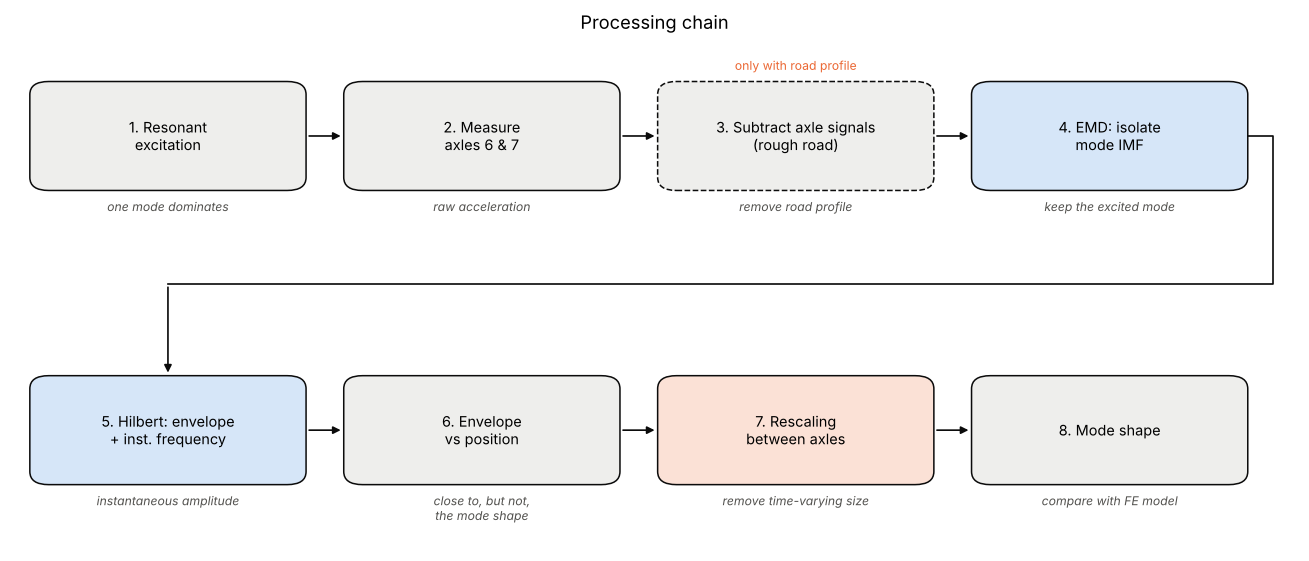

In [3]:
# Figure 2: processing chain (two rows of four boxes)
LIGHT_GRAY, LIGHT_BLUE, LIGHT_ORANGE = "#eeeeec", "#d6e6f8", "#fbe1d6"
steps = [
    ("1. Resonant\nexcitation", "one mode dominates", LIGHT_GRAY),
    ("2. Measure\naxles 6 & 7", "raw acceleration", LIGHT_GRAY),
    ("3. Subtract axle signals\n(rough road)", "remove road profile", LIGHT_GRAY),
    ("4. EMD: isolate\nmode IMF", "keep the excited mode", LIGHT_BLUE),
    ("5. Hilbert: envelope\n+ inst. frequency", "instantaneous amplitude", LIGHT_BLUE),
    ("6. Envelope\nvs position", "close to, but not,\nthe mode shape", LIGHT_GRAY),
    ("7. Rescaling\nbetween axles", "remove time-varying size", LIGHT_ORANGE),
    ("8. Mode shape", "compare with FE model", LIGHT_GRAY),
]
box_w, box_h = 0.84, 0.46
row_y = [2.1, 0.75]          # box centre y for row 1 and row 2
col_x = [0.5, 1.5, 2.5, 3.5]

fig, ax = plt.subplots(figsize=(12, 5.2))
centres = []
for i, (label, purpose, color) in enumerate(steps):
    cx, cy = col_x[i % 4], row_y[i // 4]
    centres.append((cx, cy))
    box = patches.FancyBboxPatch((cx - box_w / 2, cy - box_h / 2), box_w, box_h,
                                 boxstyle="round,pad=0.02,rounding_size=0.06",
                                 facecolor=color, edgecolor=COLOR_TRUE, lw=1,
                                 linestyle="--" if i == 2 else "-")
    ax.add_patch(box)
    ax.text(cx, cy, label, ha="center", va="center", fontsize=9.5)
    ax.text(cx, cy - box_h / 2 - 0.06, purpose, ha="center", va="top", fontsize=8,
            color="#52514e", style="italic")
ax.text(col_x[2], row_y[0] + box_h / 2 + 0.06, "only with road profile", ha="center",
        va="bottom", fontsize=8, color=COLOR_2)

arrow = dict(arrowstyle="-|>", color=COLOR_TRUE, lw=1.1)
for i in range(7):
    if i == 3:
        continue
    (x0, y0), (x1, y1) = centres[i], centres[i + 1]
    ax.annotate("", xy=(x1 - box_w / 2 - 0.02, y1), xytext=(x0 + box_w / 2 + 0.02, y0),
                arrowprops=arrow)
# Row 1 -> row 2: out of the right side of box 4, down, left, and into the top of box 5
x_right, y_mid = col_x[3] + box_w / 2 + 0.1, 1.42
ax.plot([col_x[3] + box_w / 2 + 0.02, x_right, x_right, col_x[0], col_x[0]],
        [row_y[0], row_y[0], y_mid, y_mid, y_mid], color=COLOR_TRUE, lw=1.1)
ax.annotate("", xy=(col_x[0], row_y[1] + box_h / 2 + 0.02), xytext=(col_x[0], y_mid),
            arrowprops=arrow)

ax.set_xlim(0, 4.1)
ax.set_ylim(0.2, 2.55)
ax.axis("off")
ax.set_title("Processing chain")
fig.tight_layout()
fig.savefig(FIG_DIR / "malekjafarian_obrien_2017_fig2_processing_chain.png", dpi=150,
            bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Malekjafarian y OBrien (2017).*

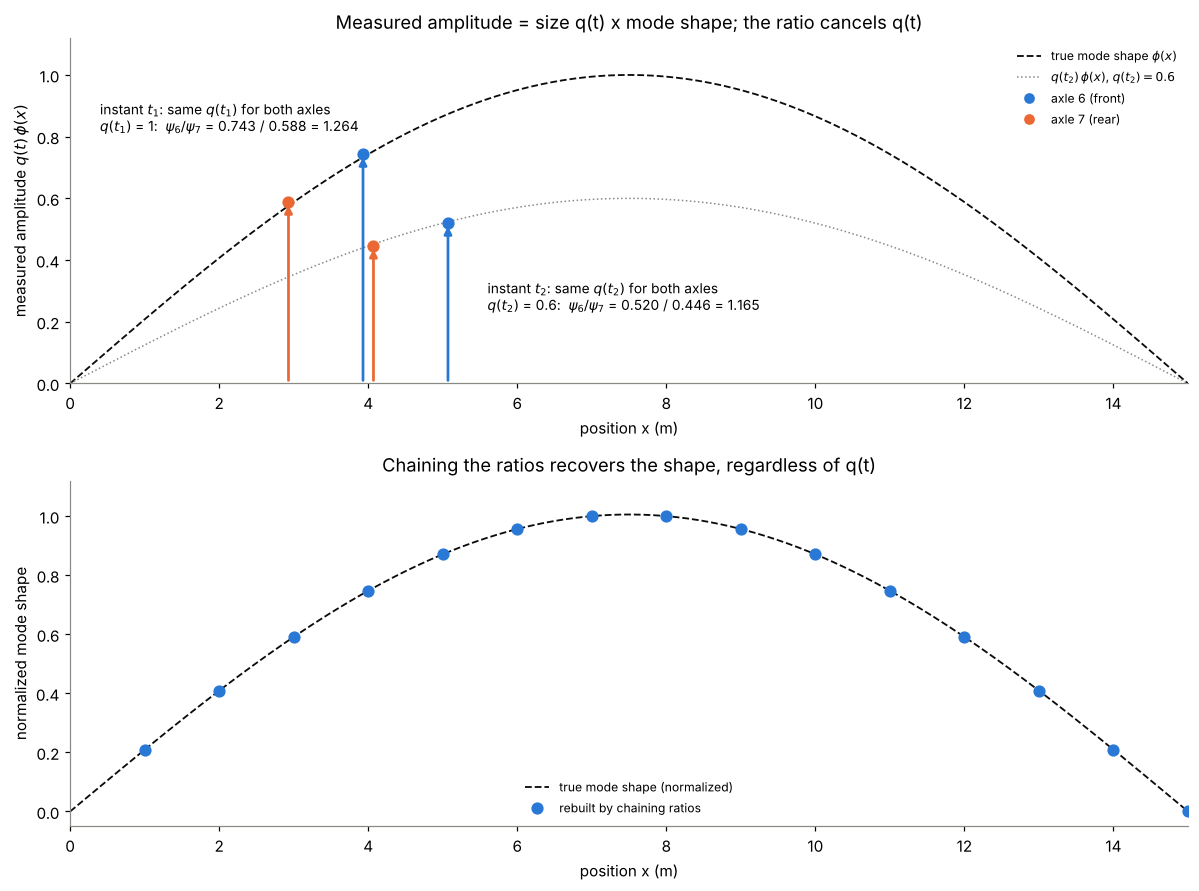

Max error between rebuilt and true shape: 2.2e-16


In [4]:
# Figure 3: rescaling between axles 6 (front) and 7 (rear)
L = 15.0
phi = lambda x: np.sin(np.pi * x / L)        # first mode shape
x_fine = np.linspace(0, L, 300)

fig, axes = plt.subplots(2, 1, figsize=(11, 8.2))

# --- Top: two instants, same q for both axles at each instant ---
ax = axes[0]
ax.plot(x_fine, phi(x_fine), "--", color=COLOR_TRUE, lw=1.2, label=r"true mode shape $\phi(x)$")
ax.plot(x_fine, 0.6 * phi(x_fine), ":", color=COLOR_SIGNAL, lw=1, label=r"$q(t_2)\,\phi(x)$, $q(t_2) = 0.6$")
instants = [("t_1", 1.0, 3.0, -0.07), ("t_2", 0.6, 4.0, 0.07)]   # name, q, rear axle x, x offset
for name, q, x_rear, dx in instants:
    x_front = x_rear + 1.0
    psi_7, psi_6 = q * phi(x_rear), q * phi(x_front)
    for x, psi, color in [(x_rear, psi_7, COLOR_2), (x_front, psi_6, COLOR_1)]:
        ax.annotate("", xy=(x + dx, psi), xytext=(x + dx, 0),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.8))
        ax.plot(x + dx, psi, "o", ms=7, color=color, zorder=3)
    text_x = 0.4 if name == "t_1" else 5.6
    text_y = 0.86 if name == "t_1" else 0.28
    ax.text(text_x, text_y,
            f"instant ${name}$: same $q({name})$ for both axles\n"
            f"$q({name})$ = {q:g}:  $\\psi_6/\\psi_7$ = {psi_6:.3f} / {psi_7:.3f} = {psi_6 / psi_7:.3f}",
            fontsize=9, va="center", ha="left")
ax.plot([], [], "o", color=COLOR_1, label="axle 6 (front)")
ax.plot([], [], "o", color=COLOR_2, label="axle 7 (rear)")
ax.set_xlim(0, L)
ax.set_ylim(0, 1.12)
ax.set_xlabel("position x (m)")
ax.set_ylabel(r"measured amplitude $q(t)\,\phi(x)$")
ax.set_title("Measured amplitude = size q(t) x mode shape; the ratio cancels q(t)")
ax.legend(loc="upper right", fontsize=8)

# --- Bottom: chain the ratios with a different random q at every step ---
rng = np.random.default_rng(0)
x_points = np.arange(1.0, L + 1.0, 1.0)              # 1, 2, ..., 15 m
phi_rebuilt = [1.0]                                   # start at phi(1) (arbitrary scale)
for x_rear in x_points[:-1]:
    q = rng.uniform(0.2, 1.5)                         # unknown, changes every step
    psi_7, psi_6 = q * phi(x_rear), q * phi(x_rear + 1.0)
    phi_rebuilt.append(phi_rebuilt[-1] * psi_6 / psi_7)
phi_rebuilt = np.array(phi_rebuilt)
phi_rebuilt_norm = phi_rebuilt / phi_rebuilt.max()
phi_true_norm = phi(x_points) / phi(x_points).max()

ax = axes[1]
ax.plot(x_fine, phi(x_fine) / phi(x_points).max(), "--", color=COLOR_TRUE, lw=1.2,
        label="true mode shape (normalized)")
ax.plot(x_points, phi_rebuilt_norm, "o", ms=7, color=COLOR_1, label="rebuilt by chaining ratios")
ax.set_xlim(0, L)
ax.set_ylim(-0.05, 1.12)
ax.set_xlabel("position x (m)")
ax.set_ylabel("normalized mode shape")
ax.set_title("Chaining the ratios recovers the shape, regardless of q(t)")
ax.legend(loc="lower center", fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "malekjafarian_obrien_2017_fig3_rescaling.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Max error between rebuilt and true shape: {np.max(np.abs(phi_rebuilt_norm - phi_true_norm)):.1e}")

*Esquema propio basado en la descripción de Malekjafarian y OBrien (2017).*

En cada instante los dos ejes ven el mismo tamaño de vibración $q(t)$, así que al dividir sus amplitudes ese tamaño se cancela y queda solo la proporción de la forma modal entre dos puntos separados 1 m. Encadenando esas proporciones se reconstruye la forma completa.

## 5. Métodos y propósito

| Método | Para qué se usó |
|---|---|
| Excitador sintonizado en el vehículo | Hacer dominar un solo modo del puente mediante resonancia |
| Dos ejes medidos a 1 m de distancia | Tener mediciones simultáneas para el reescalado |
| Resta de señales entre ejes | Eliminar el efecto de la rugosidad |
| FFT | Comprobar qué frecuencia domina en la señal |
| [EMD](../metodos/metodos.ipynb#emd) | Aislar la componente del modo excitado |
| [Transformada de Hilbert](../metodos/metodos.ipynb#transformada-de-hilbert) | Obtener la envolvente (amplitud instantánea) y confirmar la frecuencia |
| Reescalado | Convertir las envolventes en la forma modal completa |

## 6. Validación y resultados

- Solo numérica; no hay ensayo en un puente real.
- Obtuvieron los dos primeros modos con lo que los autores llaman "precisión aceptable", con carretera lisa y con rugosidad clase A. No dan MAC ni error numérico; la comparación es visual.
- Rango útil de frecuencia del excitador: de 5.4 a 5.8 Hz para el primer modo y de 22.0 a 23.2 Hz para el segundo.
- Con rugosidad clase C la precisión es pobre.

## 7. Limitaciones

- La velocidad de 2 m/s no es realista y obligaría casi a cerrar el puente.
- La fuerza necesaria, de hasta 30 kN, implica equipo pesado.
- El método es sensible al ruido, a variaciones de velocidad y a modos con frecuencias cercanas.

## 8. Conclusiones

- La excitación externa permite acceder a la energía de la respuesta del puente en las frecuencias clave.
- La amplitud medida no es la forma modal, solo está relacionada con ella en el instante de la medición; esto corrige lo que suponían estudios anteriores.
- Con el reescalado entre dos ejes consecutivos se construye la forma modal completa.
- El método puede usarse con rugosidad si se restan las señales entre ejes.